# GPT Tool-Calling Evaluation

This notebook analyzes the saved **M3SciQA validation** tool-calling evaluation in `results/tool-calling/validation/agentic-run-2026-10-31/`. It makes no model/API calls. The fresh OpenAI `gpt-4.1-mini` run considered 452 validation rows and saved per-row decisions, retrieval rankings, and failures after the agent was changed to one adaptive action per decision.

The expected action is `inspect_figures` for every figure/table question. This is a deliberately strict first-action label, not a complete measure of multi-step planning quality. Retrieval metrics rank only within M3SciQA's annotation-provided evidence passages.

## Load Saved Evaluation

In [4]:
from pathlib import Path
import json
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.figsize": (9, 5), "axes.titleweight": "bold"})

ROOT = Path.cwd()
if not (ROOT / "results/tool-calling/validation/agentic-run-2026-10-31/metrics.json").exists():
    ROOT = next(parent for parent in ROOT.parents if (parent / "results/tool-calling/validation/agentic-run-2026-10-31/metrics.json").exists())
METRICS_PATH = ROOT / "results/tool-calling/validation/agentic-run-2026-10-31/metrics.json"
SAMPLES_PATH = ROOT / "results/tool-calling/validation/agentic-run-2026-10-31/samples.json"
metrics = json.loads(METRICS_PATH.read_text(encoding="utf-8"))
sample_bundle = json.loads(SAMPLES_PATH.read_text(encoding="utf-8"))

rows = []
for sample in sample_bundle["samples"]:
    source = sample["input"]
    result = sample["output"]
    rows.append({
        "row_id": sample.get("row_id"),
        "modality": source.get("modality") or "unknown",
        "question": source.get("question", ""),
        "reference_paper_id": source.get("reference_paper_id"),
        "selected_tool": result.get("selected_tool", "answer"),
        "expected_tool": result.get("expected_tool"),
        "tool_error": result.get("tool_selection_error"),
        "retrieval_hit_at_5": result.get("recall_hit_at_k"),
        "gold_rank": result.get("gold_rank"),
        "reciprocal_rank": result.get("reciprocal_rank"),
        "top_citation_matches": result.get("top_citation_matches_reference"),
        "retrieved_papers": result.get("retrieved_papers", []),
    })

df = pd.DataFrame(rows).sort_values("row_id").reset_index(drop=True)
df["tool_correct"] = df["selected_tool"] == df["expected_tool"]
display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))
display(df.head())
print(f"Loaded {len(df)} rows: {metrics['tool_selection_provider']} / {metrics['tool_selection_model']}")

,value
dataset,M3SciQA
split,validation
tool_selection_provider,openai
tool_selection_model,gpt-4.1-mini
examples_considered,452
retrieval_examples,450
retrieval_k,5
recall_at_k,0.8533
mrr_at_k,0.7855
citation_correctness,0.74


,row_id,modality,question,reference_paper_id,selected_tool,expected_tool,tool_error,retrieval_hit_at_5,gold_rank,reciprocal_rank,top_citation_matches,retrieved_papers,tool_correct
0,0,table,Consider the paper that introduces the method ...,2309.14362,search,inspect_figures,None,True,2.0,0.5,False,"[{'paper_id': '2108.04927', 'score': 28.017189...",False
1,1,table,Consider the paper that introduces the method ...,2109.10616,search,inspect_figures,None,True,1.0,1.0,True,"[{'paper_id': '2109.10616', 'score': 36.710425...",False
2,2,table,Consider the paper that introduces the method ...,2105.06453,search,inspect_figures,None,True,1.0,1.0,True,"[{'paper_id': '2105.06453', 'score': 39.98652}...",False
3,3,table,Consider the paper that introduces the method ...,2305.12802,search,inspect_figures,None,True,1.0,1.0,True,"[{'paper_id': '2305.12802', 'score': 26.700064...",False
4,4,table,Consider the paper that introduces the dataset...,2212.09233,search,inspect_figures,None,True,1.0,1.0,True,"[{'paper_id': '2212.09233', 'score': 28.150366...",False


Loaded 452 rows: openai / gpt-4.1-mini


## Tool-Selection Summary

Summarize selected tools, accuracy by modality, model failures, and confusion against the expected visual-inspection tool.

Saved aggregate metrics


,provider,model,tool_selection_accuracy,tool_errors,recall_at_5,mrr_at_5,citation_id_match
0,openai,gpt-4.1-mini,0.0996,0,0.8533,0.7855,0.74


Selected tool counts


,selected_tool,count
0,search,407
1,inspect_figures,45


Accuracy and model errors by modality


,modality,examples,correct,accuracy,errors
0,figure,142,41,0.2887,0
1,table,310,4,0.0129,0


Error reasons Counter()


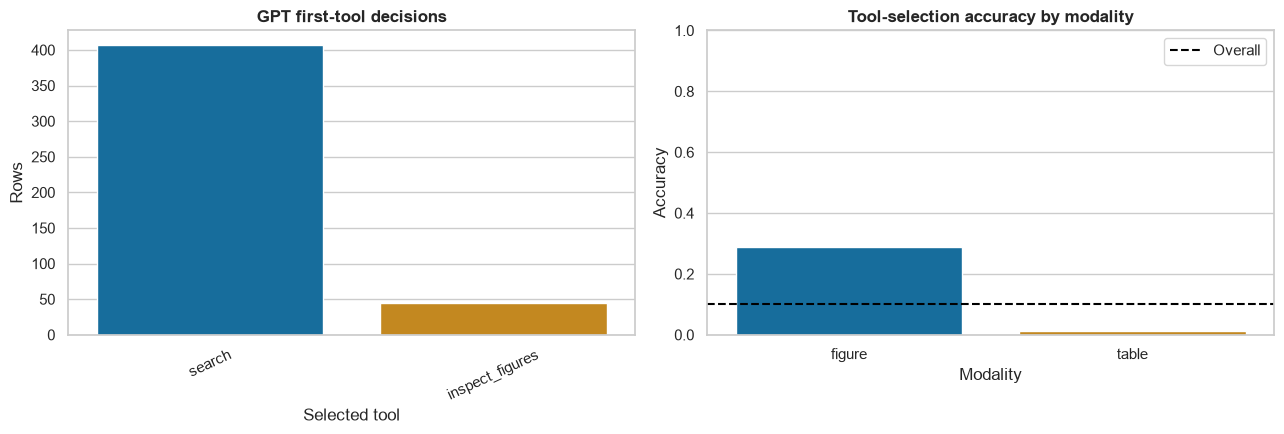

In [5]:
tool_counts = df["selected_tool"].value_counts().rename_axis("selected_tool").reset_index(name="count")
accuracy_by_modality = df.groupby("modality", observed=True).agg(
    examples=("tool_correct", "size"),
    correct=("tool_correct", "sum"),
    accuracy=("tool_correct", "mean"),
    errors=("tool_error", lambda values: values.notna().sum()),
).reset_index()
error_rows = df[df["tool_error"].notna()].copy()
error_summary = Counter(error_rows["tool_error"])

print("Saved aggregate metrics")
display(pd.DataFrame([{
    "provider": metrics["tool_selection_provider"],
    "model": metrics["tool_selection_model"],
    "tool_selection_accuracy": metrics["tool_selection_accuracy"],
    "tool_errors": metrics["tool_selection_errors"],
    "recall_at_5": metrics["recall_at_k"],
    "mrr_at_5": metrics["mrr_at_k"],
    "citation_id_match": metrics["citation_correctness"],
}]))
print("Selected tool counts")
display(tool_counts)
print("Accuracy and model errors by modality")
display(accuracy_by_modality.assign(accuracy=accuracy_by_modality["accuracy"].round(4)))
print("Error reasons", error_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=tool_counts, x="selected_tool", y="count", hue="selected_tool", legend=False, ax=axes[0])
axes[0].set(title="GPT first-tool decisions", xlabel="Selected tool", ylabel="Rows")
axes[0].tick_params(axis="x", rotation=25)
sns.barplot(data=accuracy_by_modality, x="modality", y="accuracy", hue="modality", legend=False, ax=axes[1])
axes[1].axhline(metrics["tool_selection_accuracy"], linestyle="--", color="black", label="Overall")
axes[1].set(ylim=(0, 1), title="Tool-selection accuracy by modality", xlabel="Modality", ylabel="Accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

## Retrieval and Citation Context

These retrieval metrics use M3SciQA-provided `evidence_reference` passages and compare retrieved paper IDs against the annotated `reference_arxiv_id`. They are not open-corpus retrieval or semantic entailment scores.

In [6]:
retrieval_summary = df[["retrieval_hit_at_5", "reciprocal_rank", "top_citation_matches"]].mean().rename({
    "retrieval_hit_at_5": "Recall@5",
    "reciprocal_rank": "MRR@5",
    "top_citation_matches": "Top citation ID match",
}).to_frame("score")
display(retrieval_summary.round(4))

retrieval_by_tool = df.groupby("selected_tool", observed=True).agg(
    rows=("row_id", "size"),
    recall_at_5=("retrieval_hit_at_5", "mean"),
    mrr_at_5=("reciprocal_rank", "mean"),
    citation_id_match=("top_citation_matches", "mean"),
).round(4)
display(retrieval_by_tool)

confusion = pd.crosstab(df["expected_tool"], df["selected_tool"], margins=True)
display(confusion)

print("Saved tool-call failures")
display(error_rows[["row_id", "modality", "question", "tool_error"]])

print("Largest tool-selection misses")
display(df[~df["tool_correct"]][[
    "row_id", "modality", "question", "selected_tool", "expected_tool",
    "retrieval_hit_at_5", "gold_rank", "tool_error",
]].head(12))

,score
Recall@5,0.853333
MRR@5,0.785481
Top citation ID match,0.74


,rows,recall_at_5,mrr_at_5,citation_id_match
selected_tool,,,,
inspect_figures,45,0.866667,0.8148,0.777778
search,407,0.851852,0.7822,0.735802


selected_tool,inspect_figures,search,All
expected_tool,,,
inspect_figures,45,407,452
All,45,407,452


Saved tool-call failures


,row_id,modality,question,tool_error


Largest tool-selection misses


,row_id,modality,question,selected_tool,expected_tool,retrieval_hit_at_5,gold_rank,tool_error
0,0,table,Consider the paper that introduces the method ...,search,inspect_figures,True,2.0,None
1,1,table,Consider the paper that introduces the method ...,search,inspect_figures,True,1.0,None
2,2,table,Consider the paper that introduces the method ...,search,inspect_figures,True,1.0,None
3,3,table,Consider the paper that introduces the method ...,search,inspect_figures,True,1.0,None
4,4,table,Consider the paper that introduces the dataset...,search,inspect_figures,True,1.0,None
5,5,table,Consider the paper that introduces the model t...,search,inspect_figures,True,5.0,None
6,6,table,Consider the paper that introduces the method ...,search,inspect_figures,True,1.0,None
7,7,table,Consider the paper that introduces the method ...,search,inspect_figures,False,NaN,None
8,8,figure,Consider the paper that introduces the method ...,search,inspect_figures,True,1.0,None
9,9,table,Consider the paper that introduces the transfo...,search,inspect_figures,True,1.0,None
